## Implementation of Linear regression using python

In [2]:
### import required libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error,r2_score
import matplotlib.pyplot as plt


## Load the dataset

In [3]:
DF1=pd.read_csv("weight-height.csv")

### Standardize numerical features

In [4]:
col=["Height","Weight"]
s1=MinMaxScaler()
DF1[col]=s1.fit_transform(DF1[col])
DF1.head()

,Gender,Height,Weight
0,Male,0.165212,0.863139
1,Male,0.122482,0.475476
2,Male,0.167432,0.721131
3,Male,0.147361,0.756699
4,Male,0.131761,0.689999


## Prepare dependant and independant variables

In [5]:
X=DF1[["Height"]].to_numpy()
Y=DF1[["Weight"]].to_numpy()
Y.shape

(10000, 1)

## Split the data into training and test set

In [6]:
 X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=.2,random_state=67)

In [7]:
# Create a linear regression model

model=LinearRegression()



Note: Learning more about Linear Regression model here: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html 



In [8]:
## Training  Linear regressions model 

In [9]:
model.fit(X_train,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[3.55]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[0.11]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[3.28]


In [10]:
## Calculating the Mean Squared Error (MSE) and R-squared (R2)
Y_pred=model.predict(X_test)
mse=mean_squared_error(Y_test,Y_pred)
rmse = mean_squared_error(Y_test, Y_pred) ** 0.5
mae = mean_absolute_error(Y_test, Y_pred)
r2=r2_score(Y_test,Y_pred)
print(mse)
print(rmse)
print(mae)
print(r2)

# Print model coefficients
print(model.coef_[0])
print(model.intercept_)

0.0044380478890117024
0.06661867522708405
0.054480150433493836
0.8135299373473699
[3.54709605]
[0.10829265]


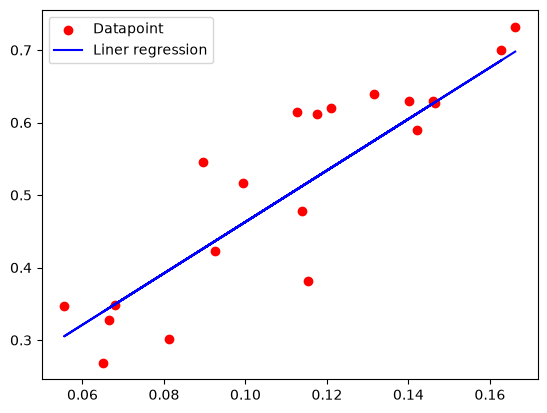

In [11]:
# Plot the linear regression Model 
plt.scatter(X_test[0:20],Y_test[0:20],color="Red",label="Datapoint")
plt.plot(X_test[0:20],Y_pred[0:20],color="Blue",label="Liner regression")
plt.legend()


In [12]:
## Load the Height and weight  to indipendent and dependent variable 

In [13]:
df2=pd.read_csv("weight-height.csv")
X = df2['Height'].values.reshape(-1, 1)
X.shape
Y=df2["Weight"].values
print(X.shape)
print(Y.shape)


(10000, 1)
(10000,)


### Z-Score Normalization

The Z-score normalization formula is:

$$
z = \frac{x-\mu}{\sigma}
$$

Where:
- $x$ = Original data value
- $\mu$ = Mean of the dataset
- $\sigma$ = Standard deviation of the dataset
- $z$ = Normalized Z-score

In [14]:
## Standardizes the features X and target variable y using Z-score normalization (also called Standardization). 
X = (X - np.mean(X, axis=0)) / np.std(X, axis=0)
Y = (Y - np.mean(Y, axis=0)) / np.std(Y, axis=0)


[![Single-Input-Linear-Neuron-Diagram.png](https://i.postimg.cc/PxYWMz4F/Single-Input-Linear-Neuron-Diagram.png)](https://postimg.cc/vg8xYnCW)

In [15]:
#add another feature to X corresponding to bias
X = np.hstack((np.ones((X.shape[0], 1)), X))
X

array([[ 1.        ,  1.75827913],
       [ 1.        ,  0.56277158],
       [ 1.        ,  1.82037531],
       ...,
       [ 1.        , -0.59704831],
       [ 1.        , 24.22511229],
       [ 1.        , -1.05110595]], shape=(10000, 2))

In [16]:
#weight or parameter initialization
theta = np.zeros(X.shape[1])
iterations=1000
# Hyperparameters
learningrate=0.01
# Gradient Descent
mseh=[]
print(X.shape)
m=X.T
print(m.shape)


(10000, 2)
(2, 10000)


<img src="https://i.postimg.cc/wMYVXD65/1.png" alt="Image Description" width="500">

In [17]:
for i in range(iterations):
    y_pred = np.dot(X, theta)
    mse = mean_squared_error(Y, y_pred)
    mseh.append(mse)

    print(f"Iteration {i+1}: MSE = {mse}")

    gradient = np.dot(X.T, (y_pred - Y)) / len(Y)
    theta -= learningrate * gradient

Iteration 1: MSE = 1.0
Iteration 2: MSE = 0.985809419277575
Iteration 3: MSE = 0.9719012311115264
Iteration 4: MSE = 0.9582698158899818
Iteration 5: MSE = 0.9449096658313463
Iteration 6: MSE = 0.9318153827588774
Iteration 7: MSE = 0.9189816759195508
Iteration 8: MSE = 0.9064033598463267
Iteration 9: MSE = 0.8940753522629599
Iteration 10: MSE = 0.8819926720305018
Iteration 11: MSE = 0.87015043713467
Iteration 12: MSE = 0.8585438627132649
Iteration 13: MSE = 0.847168259122846
Iteration 14: MSE = 0.8360190300438766
Iteration 15: MSE = 0.8250916706235781
Iteration 16: MSE = 0.8143817656557442
Iteration 17: MSE = 0.8038849877967698
Iteration 18: MSE = 0.7935970958171891
Iteration 19: MSE = 0.7835139328880019
Iteration 20: MSE = 0.7736314249011057
Iteration 21: MSE = 0.7639455788231487
Iteration 22: MSE = 0.7544524810821431
Iteration 23: MSE = 0.7451482959861835
Iteration 24: MSE = 0.7360292641736333
Iteration 25: MSE = 0.727091701094153
Iteration 26: MSE = 0.7183319955199544
Iteration 27: M

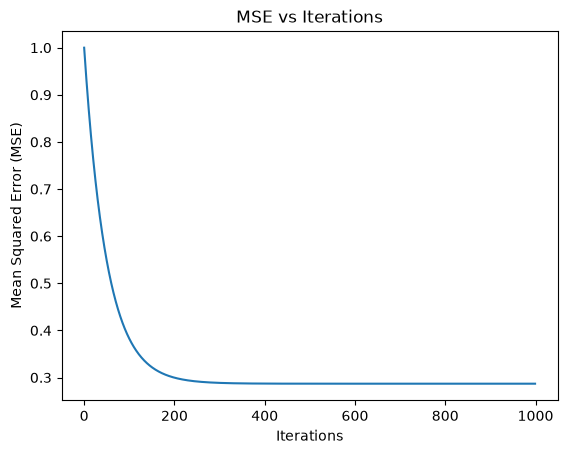

In [18]:
plt.plot(range(len(mseh)), mseh)
plt.xlabel('Iterations')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('MSE vs Iterations')
plt.show()

In [19]:
print(theta)


[1.30148203e-15 8.44412778e-01]


## You are required to fit a linear function on Food_delivery_times dataset
Description about the dataset: This dataset is designed for predicting food delivery times based on various influencing factors such as distance, weather, traffic conditions, and Preperation time. 
1. Feature selection: Consider Food_delivery_time is effected by four features (attributes) given in the dataset, which are Distance_km, Preparation_Time_min, Traffic, Weather
2. Since Traffic, Weather are having categorical values, you need to convert them into numerical using the categorical encoding methods.
3. Now, fit a linear regression model considering Distance_km, Preparation_Time_min, Traffic, and Weather as independant variables and Delivery_Time_min as dependant varibal. 


Note: In lab record, you can write the statements relevant to linear regression.

In [21]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

df = pd.read_csv("Food_Delivery_Times.csv")

# 1. Feature selection
df = df[['Distance_km', 'Preparation_Time_min', 'Traffic_Level', 'Weather', 'Delivery_Time_min']].dropna()

# 2. Categorical encoding
df['Traffic_Level'] = df['Traffic_Level'].map({'Low': 0, 'Medium': 1, 'High': 2})
df = pd.get_dummies(df, columns=['Weather'], drop_first=True)

# 3. Fit linear regression
X = df.drop('Delivery_Time_min', axis=1)
y = df['Delivery_Time_min']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

# Evaluate
y_pred = model.predict(X_test)
print("Intercept:", model.intercept_)
print("Coefficients:", dict(zip(X.columns, model.coef_)))
print("R2 score:", r2_score(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))

Intercept: 2.4696141490008117
Coefficients: {'Distance_km': np.float64(3.0162718237164525), 'Preparation_Time_min': np.float64(0.9822698680859663), 'Traffic_Level': np.float64(5.534255130303737), 'Weather_Foggy': np.float64(6.123985654667621), 'Weather_Rainy': np.float64(4.518208879351262), 'Weather_Snowy': np.float64(9.257631927417496), 'Weather_Windy': np.float64(1.8037370612940504)}
R2 score: 0.7457167609132231
MSE: 123.5671140641513
